# 💸 Transaction Fraud Classification

![Transaction Fraud Classification hero](assets/transaction_fraud_hero.svg)

**Decision Tree · A book-ready, reproducible walkthrough**

This chapter builds an educational fraud-classification pipeline from first principles. We will define the problem, create a deterministic synthetic dataset, explain the mathematics of decision trees, prevent leakage, train and evaluate a model, choose an operating threshold, save a deployable artifact, and finish with a practical checklist.

> **Safety and scope:** the labels in the default dataset are synthetic. They demonstrate workflow and model behaviour; they are not evidence that the model can detect real fraud. Never automate a financial decision from this notebook. Real use requires legal review, privacy safeguards, human review, monitoring, fairness evaluation and incident response.

## 🎯 Learning objectives

By the end of this chapter you should be able to:

1. Explain classification, class imbalance and why accuracy can mislead.
2. Derive the Gini impurity and information-gain ideas used by a Decision Tree.
3. Generate and inspect a reproducible transaction dataset without target leakage.
4. Build a preprocessing-and-model pipeline with a stratified holdout set.
5. Read a confusion matrix and calculate precision, recall, F1 and PR-AUC.
6. Select a threshold using an explicit business-cost assumption.
7. Save, reload and test the complete pipeline for a Streamlit application.

## 🧭 Real-world use cases (and boundaries)

Fraud models are commonly used as **decision-support signals**, not as final verdicts:

- **Card authorisation:** route a high-risk payment to step-up authentication.
- **E-commerce review queues:** prioritise orders for manual review before fulfilment.
- **Account protection:** trigger additional verification after an unusual login or transfer.
- **Claims triage:** rank cases for investigation while preserving a human appeal path.

A model should not silently block a person, close an account, or deny a claim. The model only estimates a pattern learned from historical labels, which may contain reporting bias and investigator bias.

## 📚 Dataset strategy and links

### Runnable default: deterministic synthetic data

The notebook generates its own data with a fixed random seed. This makes the HTML/PDF export reproducible and avoids committing private or licensed records. The label is generated from a transparent risk score so we can study the workflow without pretending that simulated fraud is real.

### Public datasets for a later extension

Use these only after reviewing their terms, label definition and feature timing:

- [ULB/Kaggle Credit Card Fraud Detection](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud) — anonymised European card transactions; Kaggle account and dataset terms apply.
- [IEEE-CIS Fraud Detection](https://www.kaggle.com/competitions/ieee-fraud-detection) — large e-commerce fraud benchmark; competition rules and access requirements apply.
- [Fraud Detection Handbook](https://fraud-detection-handbook.github.io/fraud-detection-handbook/) — open educational material and simulation-oriented examples.

Do not download a public dataset into this repository until redistribution rights and the target definition have been checked. A production dataset must also preserve time order, because a random split can overstate performance when fraud patterns drift.

## 🧠 What is a Decision Tree?

A Decision Tree recursively asks questions such as `amount > threshold?` or `channel = online?`. Each internal node is a split, each branch is an answer, and each leaf stores a prediction or class probability.

For a node containing class proportions $p_1,\ldots,p_K$, the **Gini impurity** is

$$
G(t) = 1 - \sum_{k=1}^{K} p_k^2.
$$

For binary classes, $G(t)=2p(1-p)$: it is zero when a node is pure and largest at $p=0.5$. If a parent node $t$ is split into children $t_L$ and $t_R$, the weighted impurity is

$$
G_{split} = \frac{N_L}{N_t}G(t_L) + \frac{N_R}{N_t}G(t_R),
$$

so the impurity reduction is

$$
\Delta G = G(t) - G_{split}.
$$

The tree searches candidate splits and prefers a large impurity reduction. `max_depth`, `min_samples_leaf` and pruning controls limit complexity and reduce memorisation.

## 🧮 A small split calculation

Suppose a parent has 10 transactions: 4 fraud and 6 legitimate. Then

$$G(parent)=1-(0.4^2+0.6^2)=0.48.$$

A proposed split creates a left child with 3 fraud and 1 legitimate and a right child with 1 fraud and 5 legitimate:

$$G(left)=1-(0.75^2+0.25^2)=0.375,$$
$$G(right)=1-(\frac16^2+\frac56^2)\approx0.278.$$

The weighted child impurity is $\frac4{10}(0.375)+\frac6{10}(0.278)\approx0.317$, giving $\Delta G\approx0.163$. The split makes the children more homogeneous than the parent.

## ⚖️ Metrics for rare-event classification

Let TP, FP, TN and FN denote true positives, false positives, true negatives and false negatives.

$$
Accuracy = \frac{TP+TN}{TP+TN+FP+FN}\quad	ext{(often misleading under imbalance)}
$$

$$
Precision = \frac{TP}{TP+FP},\qquad Recall = \frac{TP}{TP+FN}
$$

$$
F1 = 2\cdot\frac{Precision\cdot Recall}{Precision+Recall}.
$$

Precision asks “when we flag fraud, how often are we right?” Recall asks “how much fraud did we catch?” The precision-recall curve evaluates these trade-offs across thresholds. **PR-AUC** is usually more informative than ROC-AUC when the positive class is rare.

A probability threshold is an operating policy, not a universal truth. If missing fraud costs $C_{FN}$ and reviewing a legitimate transaction costs $C_{FP}$, a simple evaluation cost is $C_{FN}FN+C_{FP}FP$. Real teams should use validated, documented costs and monitor them over time.

## 🛠️ Imports and reproducibility

The core tools are:

- **Python 3.12** — execution environment.
- **pandas / NumPy** — tabular data and numerical simulation.
- **Matplotlib / Seaborn** — publication-friendly charts.
- **scikit-learn** — preprocessing, Decision Tree, metrics and model selection.
- **joblib** — trusted local artifact persistence.
- **Jupyter / nbconvert** — executable notebook and HTML/PDF publishing.
- **Streamlit** — optional educational UI layer after review.

The dependency versions are pinned in this project’s `requirements.txt` so the saved artifact and serving environment agree.

In [46]:
from pathlib import Path
import json
import platform

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, average_precision_score,
    classification_report, confusion_matrix, f1_score, precision_score,
    precision_recall_curve, recall_score, roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree

RANDOM_STATE = 42
ROOT = Path.cwd()
ARTIFACT_DIR = ROOT / "artifacts"
ARTIFACT_DIR.mkdir(exist_ok=True)

print(f"Python: {platform.python_version()}")
print(f"scikit-learn: {sklearn.__version__}")
print(f"Working directory: {ROOT}")

Python: 3.12.13
scikit-learn: 1.6.1
Working directory: /Users/abhishekpanda/Documents/machine-learning-algorithms/02-decision-tree/02-transaction-fraud-classification


## 1. Generate a transparent synthetic dataset

We create transaction fields that could plausibly exist **before** a transaction is reviewed: amount, channel, country distance, device age, transactions in the last hour, account age, authentication strength and merchant category. The target is generated from a hidden risk score plus noise.

We intentionally do **not** include fields such as `investigation_result`, `chargeback_confirmed` or `reviewer_decision`; those would be post-outcome leakage. In a real project, confirm the timestamp at which every feature becomes available.

In [47]:
def make_synthetic_transactions(n_rows: int = 20_000, seed: int = RANDOM_STATE) -> pd.DataFrame:
    rng = np.random.default_rng(seed)
    channels = np.array(["card_present", "online", "mobile_wallet", "bank_transfer"])
    categories = np.array(["grocery", "electronics", "travel", "gaming", "fashion", "utilities"])
    channel = rng.choice(channels, size=n_rows, p=[0.38, 0.36, 0.14, 0.12])
    category = rng.choice(categories, size=n_rows, p=[0.25, 0.18, 0.12, 0.10, 0.18, 0.17])
    amount = np.clip(rng.lognormal(mean=3.7, sigma=1.0, size=n_rows), 2, 2500)
    distance = np.clip(rng.gamma(shape=1.8, scale=85, size=n_rows), 0, 1200)
    device_age = np.clip(rng.exponential(scale=220, size=n_rows), 0, 1800)
    velocity = np.clip(rng.poisson(lam=2.2, size=n_rows), 0, 25)
    account_age = np.clip(rng.exponential(scale=500, size=n_rows), 1, 3000)
    auth = rng.choice(["strong", "standard", "failed"], size=n_rows, p=[0.62, 0.30, 0.08])
    weekend = rng.integers(0, 2, size=n_rows)

    score = (
        -5.0
        + 0.0018 * amount
        + 0.0020 * distance
        + 0.0015 * velocity ** 2
        - 0.0005 * account_age
        + (channel == "online") * 0.55
        + (channel == "bank_transfer") * 0.35
        + (category == "electronics") * 0.30
        + (category == "gaming") * 0.50
        + (auth == "failed") * 1.40
        + (auth == "standard") * 0.25
        + weekend * 0.15
        + rng.normal(0, 0.65, n_rows)
    )
    probability = 1 / (1 + np.exp(-score))
    fraud = rng.binomial(1, probability)

    return pd.DataFrame({
        "amount": amount.round(2),
        "channel": channel,
        "merchant_category": category,
        "distance_from_usual_km": distance.round(2),
        "device_age_days": device_age.round(1),
        "transactions_last_hour": velocity,
        "account_age_days": account_age.round(1),
        "authentication": auth,
        "is_weekend": weekend,
        "is_fraud": np.where(fraud == 1, "fraud", "legitimate"),
    })

df = make_synthetic_transactions()
df.head()

,amount,channel,merchant_category,distance_from_usual_km,device_age_days,transactions_last_hour,account_age_days,authentication,is_weekend,is_fraud
0,74.37,mobile_wallet,fashion,142.84,115.3,2,71.5,strong,1,legitimate
1,2.47,online,utilities,139.87,33.2,7,1129.1,strong,0,legitimate
2,97.08,mobile_wallet,grocery,40.99,81.7,4,188.2,strong,0,legitimate
3,32.83,online,grocery,132.73,248.9,0,300.9,strong,1,legitimate
4,12.91,card_present,gaming,30.07,149.7,1,90.7,strong,1,legitimate


In [48]:
print(f"Rows: {len(df):,}")
print(f"Columns: {df.shape[1]}")
print(f"Fraud rate: {(df['is_fraud'] == 'fraud').mean():.2%}")
df.isna().sum().to_frame("missing_values").T

Rows: 20,000
Columns: 10
Fraud rate: 2.11%


,amount,channel,merchant_category,distance_from_usual_km,device_age_days,transactions_last_hour,account_age_days,authentication,is_weekend,is_fraud
missing_values,0,0,0,0,0,0,0,0,0,0


### First inspection

The fraud rate is intentionally low enough to demonstrate imbalance. Always compare the positive-class rate with the model metrics; a model that predicts “legitimate” for every row can have high accuracy while catching zero fraud.

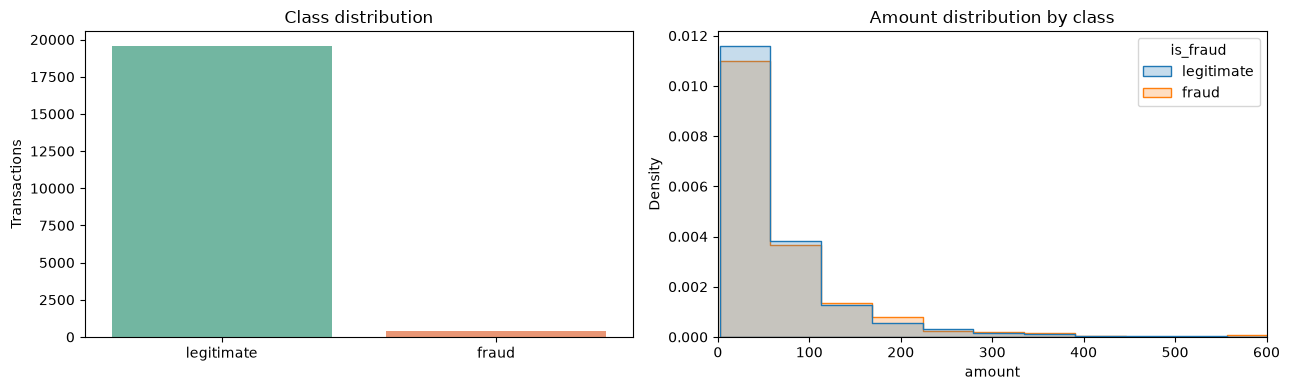

In [49]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.countplot(data=df, x="is_fraud", ax=axes[0], hue="is_fraud", legend=False, palette="Set2")
axes[0].set_title("Class distribution")
axes[0].set_xlabel("")
axes[0].set_ylabel("Transactions")
sns.histplot(data=df, x="amount", hue="is_fraud", bins=45, element="step", stat="density", common_norm=False, ax=axes[1])
axes[1].set_title("Amount distribution by class")
axes[1].set_xlim(0, 600)
plt.tight_layout()

## 2. Define features and protect against leakage

The target is `is_fraud`. Every input below is intended to be available at authorisation time. We split before fitting imputers or encoders. This prevents information from the test set influencing training transformations.

In [50]:
TARGET = "is_fraud"
FEATURES = [
    "amount", "channel", "merchant_category", "distance_from_usual_km",
    "device_age_days", "transactions_last_hour", "account_age_days",
    "authentication", "is_weekend",
]
X = df[FEATURES].copy()
y = df[TARGET].copy()

numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(exclude=["number"]).columns.tolist()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
print(f"Train rows: {len(X_train):,}; test rows: {len(X_test):,}")
print(f"Train fraud rate: {(y_train == 'fraud').mean():.2%}")
print(f"Test fraud rate:  {(y_test == 'fraud').mean():.2%}")

Train rows: 16,000; test rows: 4,000
Train fraud rate: 2.11%
Test fraud rate:  2.12%


## 3. Build a leakage-safe preprocessing pipeline

A `ColumnTransformer` applies numeric and categorical preparation separately:

- Numeric columns use median imputation.
- Categorical columns use most-frequent imputation and one-hot encoding.
- `handle_unknown="ignore"` makes unseen serving categories safe.

The pipeline is fitted only on `X_train`. Saving the entire pipeline is important: the serving app must apply exactly the same transformations as training.

In [51]:
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
])
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])
preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features),
])

baseline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", DummyClassifier(strategy="most_frequent")),
])
baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)
print(classification_report(y_test, baseline_pred, zero_division=0))

              precision    recall  f1-score   support

       fraud       0.00      0.00      0.00        85
  legitimate       0.98      1.00      0.99      3915

    accuracy                           0.98      4000
   macro avg       0.49      0.50      0.49      4000
weighted avg       0.96      0.98      0.97      4000



## 4. Train the Decision Tree

`class_weight="balanced"` gives more influence to the minority class during split selection. `max_depth=6` and `min_samples_leaf=30` are deliberately conservative: a deep tree can memorise noise and produce unstable rules. These are teaching defaults, not universal production settings.

In [52]:
tree_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        criterion="gini", max_depth=6, min_samples_leaf=30,
        class_weight="balanced", random_state=RANDOM_STATE,
    )),
])
tree_pipeline.fit(X_train, y_train)
probability_fraud = tree_pipeline.predict_proba(X_test)[:, list(tree_pipeline.classes_).index("fraud")]
prediction_default = np.where(probability_fraud >= 0.50, "fraud", "legitimate")
print(classification_report(y_test, prediction_default, zero_division=0))

              precision    recall  f1-score   support

       fraud       0.04      0.29      0.07        85
  legitimate       0.98      0.85      0.91      3915

    accuracy                           0.84      4000
   macro avg       0.51      0.57      0.49      4000
weighted avg       0.96      0.84      0.89      4000



In [53]:
def metric_summary(y_true, predictions, probabilities=None) -> dict[str, float]:
    result = {
        "accuracy": accuracy_score(y_true, predictions),
        "precision": precision_score(y_true, predictions, pos_label="fraud", zero_division=0),
        "recall": recall_score(y_true, predictions, pos_label="fraud", zero_division=0),
        "f1": f1_score(y_true, predictions, pos_label="fraud", zero_division=0),
    }
    if probabilities is not None:
        result["pr_auc"] = average_precision_score(y_true == "fraud", probabilities)
        result["roc_auc"] = roc_auc_score(y_true == "fraud", probabilities)
    return result

metrics = pd.DataFrame({
    "baseline": metric_summary(y_test, baseline_pred),
    "decision_tree": metric_summary(y_test, prediction_default, probability_fraud),
}).T
metrics.round(3)

,accuracy,precision,recall,f1,pr_auc,roc_auc
baseline,0.979,0.000,0.000,0.000,NaN,NaN
decision_tree,0.838,0.041,0.294,0.072,0.048,0.564


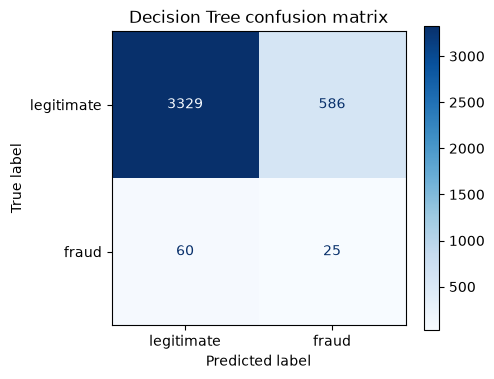

In [54]:
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test, prediction_default, labels=["legitimate", "fraud"], cmap="Blues", ax=ax
)
ax.set_title("Decision Tree confusion matrix")
plt.tight_layout()

## 5. Inspect the learned tree

The tree is interpretable as a sequence of conditions, but interpretability does not mean causality. A feature used near the root is useful for separating this sample; it is not proof that the feature causes fraud.

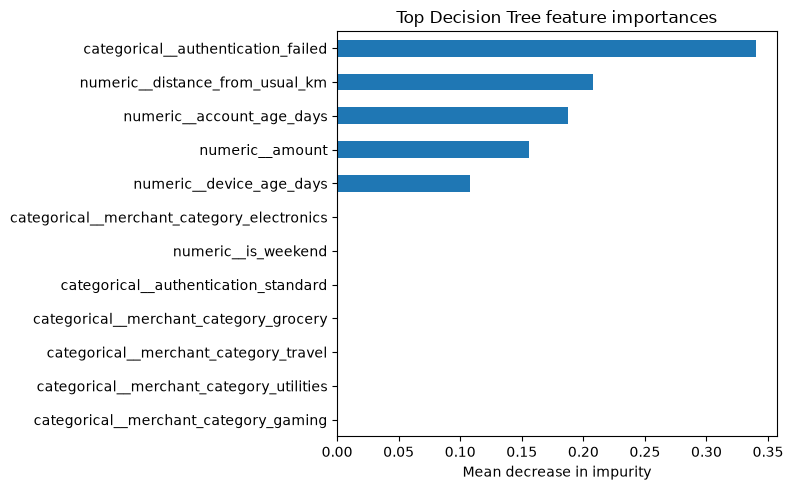

In [55]:
classifier = tree_pipeline.named_steps["classifier"]
feature_names = tree_pipeline.named_steps["preprocessor"].get_feature_names_out()
importance = pd.Series(classifier.feature_importances_, index=feature_names).sort_values(ascending=False)
importance.head(12).sort_values().plot.barh(figsize=(8, 5), title="Top Decision Tree feature importances")
plt.xlabel("Mean decrease in impurity")
plt.tight_layout()

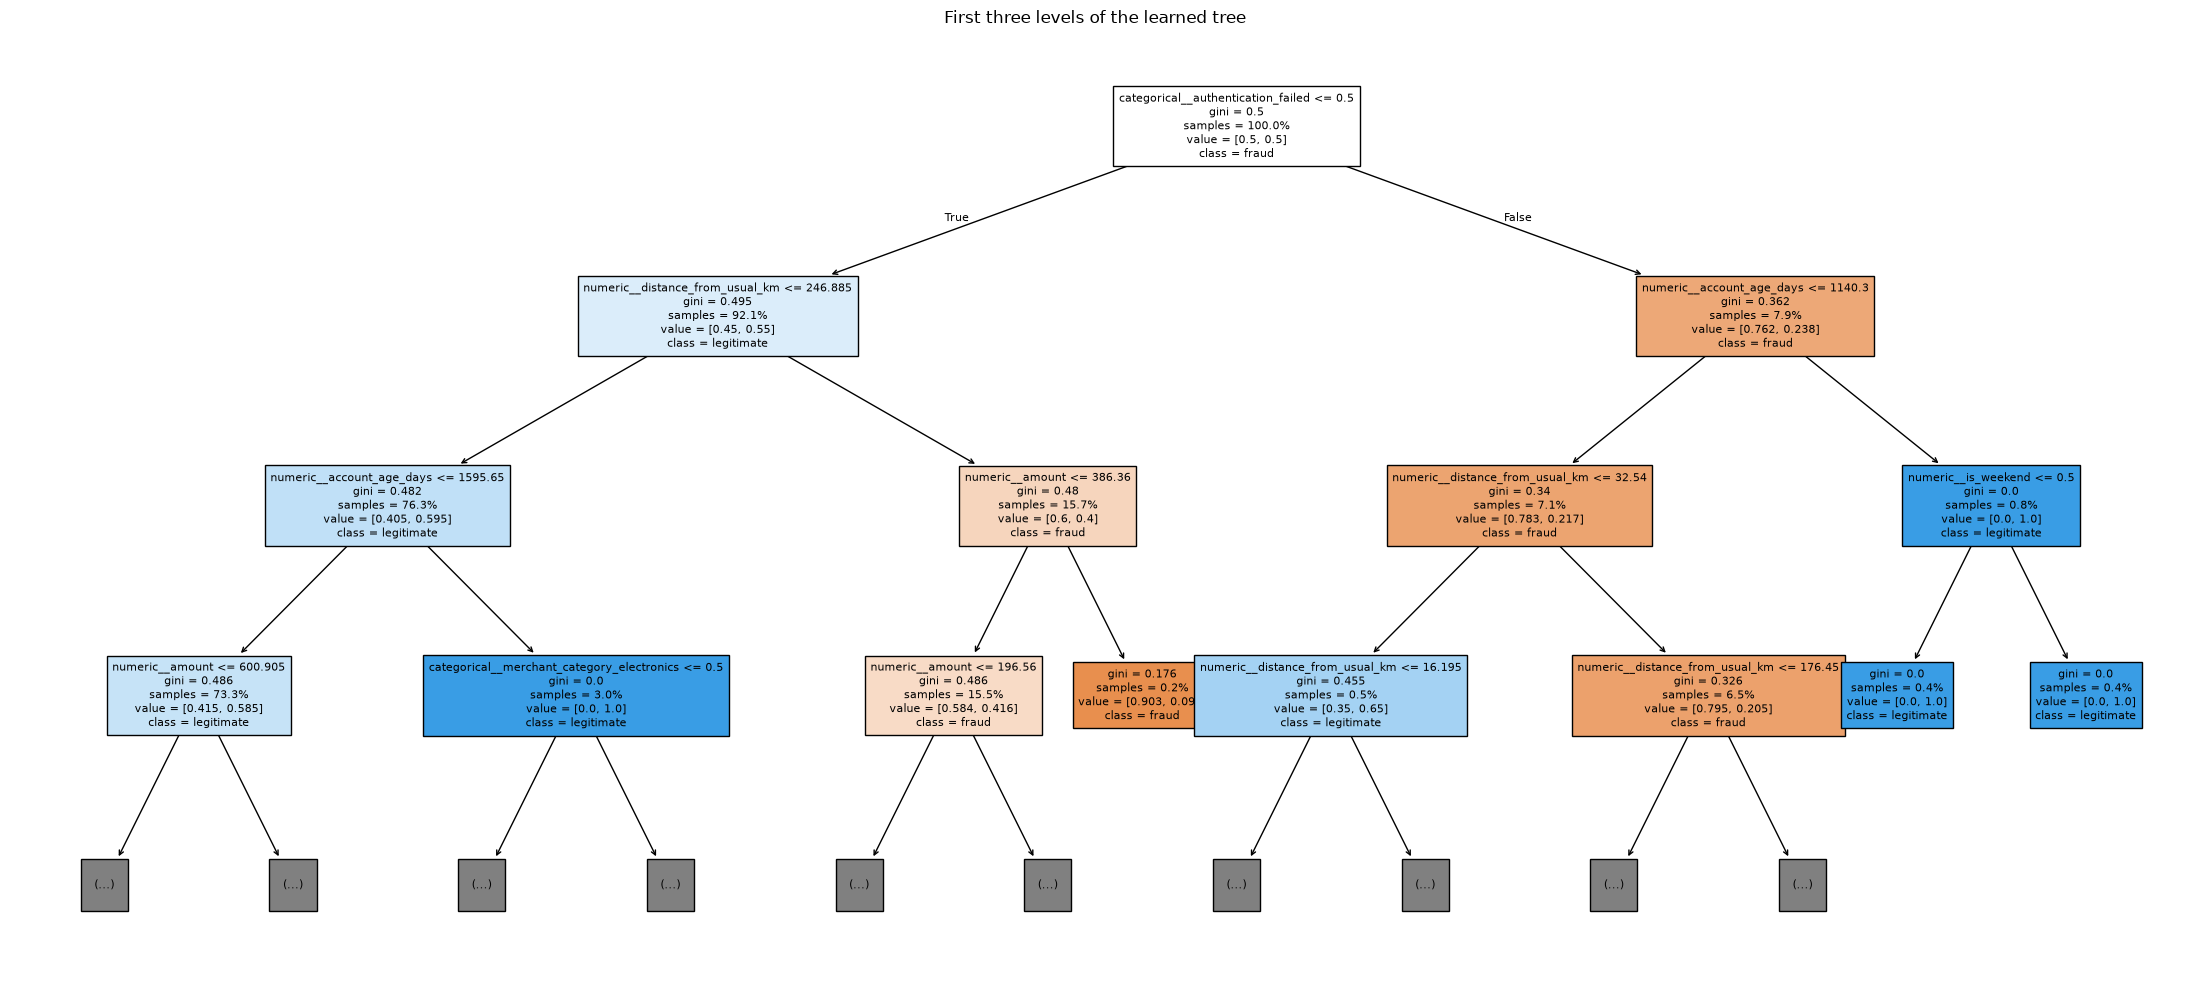

In [56]:
plt.figure(figsize=(22, 10))
plot_tree(
    classifier, feature_names=feature_names, class_names=classifier.classes_,
    filled=True, max_depth=3, fontsize=8, impurity=True, proportion=True
)
plt.title("First three levels of the learned tree")
plt.tight_layout()

## 6. Choose a threshold with an explicit cost assumption

`predict()` uses a default threshold of 0.50. Fraud operations often choose another threshold because false negatives and false positives have different consequences. Here we show a transparent illustrative policy:

- $C_{FN}=10$: missing fraud is ten cost units.
- $C_{FP}=1$: sending a legitimate payment to review is one cost unit.

We select the threshold with the lowest holdout cost only as an educational example. In real work, choose the threshold on a validation set and report performance on a separate untouched test set.

threshold      0.910000
precision      0.200000
recall         0.058824
f1             0.090909
cost         820.000000
fp            20.000000
fn            80.000000


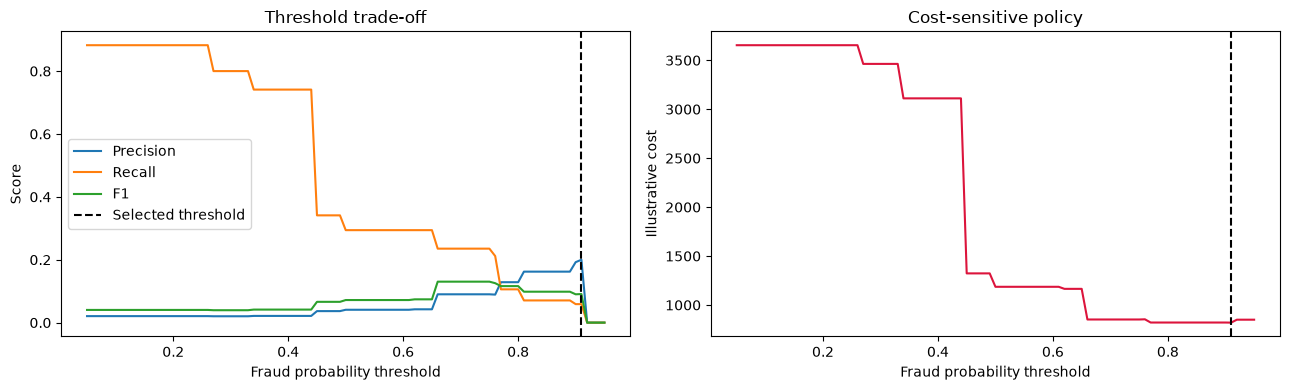

In [57]:
thresholds = np.linspace(0.05, 0.95, 91)
rows = []
for threshold in thresholds:
    pred = np.where(probability_fraud >= threshold, "fraud", "legitimate")
    tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=["legitimate", "fraud"]).ravel()
    rows.append({
        "threshold": threshold, "precision": precision_score(y_test, pred, pos_label="fraud", zero_division=0),
        "recall": recall_score(y_test, pred, pos_label="fraud", zero_division=0),
        "f1": f1_score(y_test, pred, pos_label="fraud", zero_division=0),
        "cost": 10 * fn + fp, "fp": fp, "fn": fn,
    })
threshold_table = pd.DataFrame(rows)
best = threshold_table.loc[threshold_table["cost"].idxmin()]
print(best.to_string())

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(threshold_table["threshold"], threshold_table["precision"], label="Precision")
ax[0].plot(threshold_table["threshold"], threshold_table["recall"], label="Recall")
ax[0].plot(threshold_table["threshold"], threshold_table["f1"], label="F1")
ax[0].axvline(best["threshold"], color="black", linestyle="--", label="Selected threshold")
ax[0].set(xlabel="Fraud probability threshold", ylabel="Score", title="Threshold trade-off")
ax[0].legend()
ax[1].plot(threshold_table["threshold"], threshold_table["cost"], color="crimson")
ax[1].axvline(best["threshold"], color="black", linestyle="--")
ax[1].set(xlabel="Fraud probability threshold", ylabel="Illustrative cost", title="Cost-sensitive policy")
plt.tight_layout()

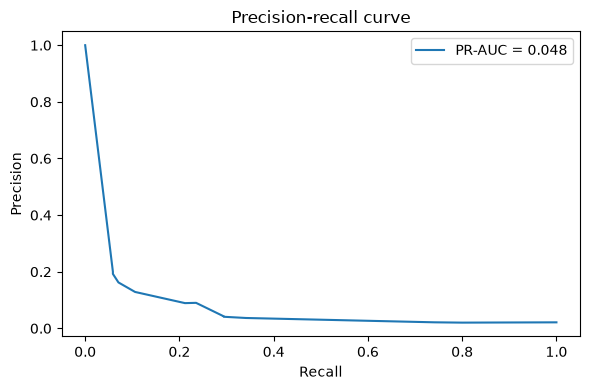

In [58]:
precision_curve, recall_curve, curve_thresholds = precision_recall_curve(
    y_test == "fraud", probability_fraud
)
plt.figure(figsize=(6, 4))
plt.plot(recall_curve, precision_curve, label=f"PR-AUC = {average_precision_score(y_test == 'fraud', probability_fraud):.3f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-recall curve")
plt.legend()
plt.tight_layout()

## 7. Save and reload the complete artifact

Only load artifacts you created or explicitly trust: joblib uses pickle-based serialization and untrusted files can execute code. The metadata records the training contract so a deployment can check its expected target, features and library version.

In [59]:
MODEL_PATH = ARTIFACT_DIR / "transaction_fraud_tree_pipeline.joblib"
METADATA_PATH = ARTIFACT_DIR / "model_metadata.json"
joblib.dump(tree_pipeline, MODEL_PATH)
metadata = {
    "algorithm": "DecisionTreeClassifier",
    "project": "transaction-fraud-classification",
    "target_column": TARGET,
    "positive_class": "fraud",
    "input_features": FEATURES,
    "classes": tree_pipeline.classes_.tolist(),
    "selected_threshold": float(best["threshold"]),
    "illustrative_false_negative_cost": 10,
    "illustrative_false_positive_cost": 1,
    "sklearn_version": sklearn.__version__,
    "python_version": platform.python_version(),
    "dataset": "deterministic synthetic transactions; see notebook for public dataset links",
    "educational_only": True,
}
METADATA_PATH.write_text(json.dumps(metadata, indent=2) + "\n", encoding="utf-8")

loaded = joblib.load(MODEL_PATH)
assert loaded.predict(X_test.head(5)).shape == (5,)
assert json.loads(METADATA_PATH.read_text())["input_features"] == FEATURES
print(f"Saved {MODEL_PATH}")
print(f"Saved {METADATA_PATH}")
print("Round-trip artifact test passed.")

Saved /Users/abhishekpanda/Documents/machine-learning-algorithms/02-decision-tree/02-transaction-fraud-classification/artifacts/transaction_fraud_tree_pipeline.joblib
Saved /Users/abhishekpanda/Documents/machine-learning-algorithms/02-decision-tree/02-transaction-fraud-classification/artifacts/model_metadata.json
Round-trip artifact test passed.


## 8. Example serving prediction

A Streamlit app should validate inputs, load the artifact once with `st.cache_resource`, display the probability and threshold, and clearly state that the result is a review signal—not a verdict. The app must use the same feature names and types as this notebook.

In [60]:
example_transaction = pd.DataFrame([{
    "amount": 850.0, "channel": "online", "merchant_category": "electronics",
    "distance_from_usual_km": 420.0, "device_age_days": 8.0,
    "transactions_last_hour": 7, "account_age_days": 90.0,
    "authentication": "standard", "is_weekend": 1,
}])
example_probability = loaded.predict_proba(example_transaction)[0, list(loaded.classes_).index("fraud")]
print(f"Estimated fraud probability: {example_probability:.1%}")
print(f"Review signal at selected threshold: {example_probability >= metadata['selected_threshold']}")

Estimated fraud probability: 90.3%
Review signal at selected threshold: False


## ✅ Final summary and reproducibility checklist

### What we learned

- A Decision Tree partitions feature space through impurity-reducing questions.
- Gini impurity measures class mixing; depth and leaf-size controls limit overfitting.
- Accuracy alone is unsafe for rare fraud; precision, recall, F1 and PR-AUC reveal different trade-offs.
- A threshold is an operational policy that should be tied to documented costs.
- Leakage prevention and time-aware validation matter as much as the algorithm.
- A saved preprocessing-and-model pipeline is safer than saving a classifier without its transformations.

### Before sharing this project

- [x] Synthetic dataset is deterministic and clearly labelled as synthetic.
- [x] Public dataset links and access/licensing cautions are documented.
- [x] Target leakage fields are excluded.
- [x] Train/test split is stratified and transformations fit on training data only.
- [x] Baseline, confusion matrix, precision, recall, F1, ROC-AUC and PR-AUC are reported.
- [x] Threshold trade-off and illustrative cost assumptions are visible.
- [x] Pipeline and metadata are saved and reloaded.
- [ ] Validate on an approved real dataset with time-based splitting.
- [ ] Complete privacy, fairness, governance and security review.
- [x] Streamlit profile and app directory: [https://share.streamlit.io/user/abhishekpandaofficial](https://share.streamlit.io/user/abhishekpandaofficial).

### Project tools

Python 3.12 · Jupyter · pandas · NumPy · Matplotlib · Seaborn · scikit-learn · joblib · nbconvert · Streamlit · Git/GitHub.

### 🚀 Streamlit

[![Streamlit](assets/streamlit_logo.svg)](https://share.streamlit.io/user/abhishekpandaofficial)

Browse the deployed project apps from the [Streamlit profile and app directory](https://share.streamlit.io/user/abhishekpandaofficial).
